# ChoixSocial-11 — Vote par approbation : un bulletin qui n'est pas un classement

**Série GameTheory / SocialChoice** · C# (.NET Interactive) · BCL seul pour les algorithmes (0 NuGet) · Figure ScottPlot 5

**Navigation** : [<< ChoixSocial-10 (précédent)](ChoixSocial-10-Manipulation-Strategique-MultiWinner-CSharp.ipynb) | [Index](README.md)

Le carnet **01** (Arrow) a établi qu'*aucune* règle de vote à au moins trois candidats ne
satisfait à la fois la propriété de Pareto, l'indépendance des alternatives superflues (IIA) et
le non-dictatorat. Ce carnet prend le contre-pied : au lieu de chercher une règle impossible, on
étudie une règle **réelle** — le **vote par approbation** — et on mesure **ce qu'elle abandonne**
(le classement complet) contre **ce qu'elle change** (le prix d'un bulletin stratégique).

**Le fil du carnet.**

1. On écrit trois règles from scratch — pluralité, Borda, approbation — et on cherche un profil
   où elles ne donnent pas le même gagnant.
2. On fait tenter un calculateur, seul puis à plusieurs, et on demande quels bulletins un électeur
   peut déposer sans jamais le regretter.
3. On passe l'axiome d'indépendance (IIA) au compteur, comme le carnet 01 l'a fait pour Borda.
   C'est la partie qui surprend : sur ses propres bulletins, l'approbation ne montre **aucune**
   violation.
4. Quatre exercices jalonnent le parcours, dont un sur la dominance.


In [1]:
using System;
using System.Collections.Generic;
using System.Linq;

// C# / .NET Interactive — BCL seul pour les algorithmes (0 NuGet).
// La figure utilise ScottPlot 5, comme les jumeaux C# de la série.

Console.WriteLine(".NET " + Environment.Version);
Console.WriteLine("ChoixSocial-11 — Vote par approbation");


The below script needs to be able to find the current output cell; this is an easy method to get it.

.NET 10.0.15


ChoixSocial-11 — Vote par approbation


## Que change le vote par approbation ?

Les règles de **classement** (pluralité, Borda, IRV) obligent chaque votant à **hiérarchiser**
les candidats. Le vote par approbation casse cette contrainte :

- chaque votant **approuve un sous-ensemble** de candidats (aucun, un, plusieurs, tous) ;
- le **score** d'un candidat est le nombre de votants qui l'approuvent ;
- le **gagnant** est le candidat au score d'approbation le plus élevé.

Un bulletin d'approbation est donc une *ligne de partage*, pas un ordre. Avec trois candidats
`A`, `B`, `C`, un électeur peut déposer huit bulletins différents, de l'ensemble vide à
l'ensemble complet, là où il n'existe que six classements stricts. Les huit ne disent pas la même
chose que les six : le bulletin `{A, B}` affirme que `A` et `B` sont approuvés, sans dire lequel
est préféré.

Autrement dit, un bulletin est un classement à **deux niveaux** — approuvés, non approuvés — et
sans ordre à l'intérieur de chaque niveau.

- **Ce que la règle entend** : approuvé, ou non approuvé.
- **Ce qu'elle n'entend pas** : qui est en tête. Un candidat approuvé par tous comme second choix
  marque le score maximal, comme le ferait un candidat classé premier par tous.

Ce qu'on abandonne est donc clair : l'ordre complet. Ce carnet mesure ce que coûte cet abandon —
d'abord le prix d'un bulletin calculé, puis le sort de l'axiome d'indépendance d'Arrow.


In [2]:
using System;
using System.Collections.Generic;
using System.Linq;

// Les trois règles, from scratch en BCL (0 NuGet). Un bulletin d'approbation est un
// ensemble de candidats ; un bulletin de classement est une liste ordonnée.
static class C11
{
    // Score d'approbation : nombre de votants qui approuvent chaque candidat.
    public static Dictionary<string, int> ScoresApprobation(IList<HashSet<string>> bulletins, IEnumerable<string> cands)
    {
        var scores = cands.ToDictionary(c => c, _ => 0);
        foreach (var b in bulletins)
            foreach (var c in b)
                if (scores.ContainsKey(c)) scores[c] += 1;
        return scores;
    }

    // Gagnant par approbation (ex-aequo : premier alphabétiquement, pour rester déterministe).
    public static string GagnantApprobation(IList<HashSet<string>> bulletins, IEnumerable<string> cands)
    {
        return ScoresApprobation(bulletins, cands)
            .OrderByDescending(kv => kv.Value).ThenBy(kv => kv.Key).First().Key;
    }

    // Pluralité : une voix pour le premier de chaque bulletin de classement.
    public static Dictionary<string, int> ScoresPluralite(IList<List<string>> classements, IEnumerable<string> cands)
    {
        var scores = cands.ToDictionary(c => c, _ => 0);
        foreach (var cl in classements)
            if (cl.Count > 0) scores[cl[0]] += 1;
        return scores;
    }

    public static string GagnantPluralite(IList<List<string>> classements, IEnumerable<string> cands)
    {
        return ScoresPluralite(classements, cands)
            .OrderByDescending(kv => kv.Value).ThenBy(kv => kv.Key).First().Key;
    }

    // Borda : n-1, n-2, ... points décroissants.
    public static Dictionary<string, int> ScoresBorda(IList<List<string>> classements, IEnumerable<string> cands)
    {
        int n = cands.Count();
        var scores = cands.ToDictionary(c => c, _ => 0);
        foreach (var cl in classements)
            for (int i = 0; i < cl.Count && i < n; i++)
                scores[cl[i]] += (n - 1 - i);
        return scores;
    }

    public static string GagnantBorda(IList<List<string>> classements, IEnumerable<string> cands)
    {
        return ScoresBorda(classements, cands)
            .OrderByDescending(kv => kv.Value).ThenBy(kv => kv.Key).First().Key;
    }
}

Console.WriteLine("Règles chargées : " + typeof(C11).Name);


Règles chargées : C11


## L'expérience : trois règles, deux réponses

On construit un petit profil où les règles **divergent** : un électorat divisé entre deux camps,
avec un **candidat de compromis** que les deux camps classent en second. Trois couples de
fonctions sont à lire dans la cellule — chacun un score, un gagnant.

- **Pluralité** : `ScoresPluralite` ne compte que le premier de chaque classement (`cl[0]`).
- **Borda** : `ScoresBorda` attribue `n - 1 - i` points au candidat en position `i` — deux, un,
  zéro avec trois candidats.
- **Approbation** : `ScoresApprobation` parcourt les bulletins une fois ; le score de `A`
  additionne les bulletins qui contiennent `A`, sans regarder qui d'autre s'y trouve.

Le gagnant est le score le plus élevé, les ex-æquo étant départagés par ordre alphabétique. Ce
départage est arbitraire, mais déterministe — et il n'est pas neutre : le carnet montrera qu'un
calcul peut ne payer que par l'égalité qu'il crée.

**Le profil.** Quatre électeurs du camp `A` classent `A > B > C`, deux du camp `C` classent
`C > B > A`. Les bulletins d'approbation approuvent chacun son candidat **et** le compromis `B`.
On attend que la pluralité élise le favori du plus grand camp, que Borda tienne compte des
seconds choix — sans inverser le résultat ici —, et que l'approbation élise le candidat que le
plus de monde accepte. Le « bon » résultat dépend de ce que l'on veut préserver — c'est la
tension d'Arrow, rendue arithmétique.


In [3]:
// 6 votants, 3 candidats : A (candidat du camp 1), B (compromis), C (candidat du camp 2).
// 4 votants du camp A (A > B > C), 2 du camp C (C > B > A). B est le consensus des deux camps.
string[] cands11 = { "A", "B", "C" };

// Bulletins de classement (pour la pluralité et Borda).
List<List<string>> classements11 = new List<List<string>>
{
    new List<string> { "A", "B", "C" },
    new List<string> { "A", "B", "C" },
    new List<string> { "A", "B", "C" },
    new List<string> { "A", "B", "C" },
    new List<string> { "C", "B", "A" },
    new List<string> { "C", "B", "A" },
};

// Bulletins d'approbation : chacun approuve SON premier choix ET le compromis B.
// -> B récolte 6 approbations, A et C seulement 4 et 2.
List<HashSet<string>> approval11 = new List<HashSet<string>>
{
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "C", "B" },
    new HashSet<string> { "C", "B" },
};

Console.WriteLine($"Pluralité   -> {C11.GagnantPluralite(classements11, cands11)}   ({string.Join(", ", C11.ScoresPluralite(classements11, cands11).Select(kv => kv.Key + "=" + kv.Value))})");
Console.WriteLine($"Borda       -> {C11.GagnantBorda(classements11, cands11)}   ({string.Join(", ", C11.ScoresBorda(classements11, cands11).Select(kv => kv.Key + "=" + kv.Value))})");
Console.WriteLine($"Approbation -> {C11.GagnantApprobation(approval11, cands11)}   ({string.Join(", ", C11.ScoresApprobation(approval11, cands11).Select(kv => kv.Key + "=" + kv.Value))})");


Pluralité   -> A   (A=4, B=0, C=2)


Borda       -> A   (A=8, B=6, C=4)


Approbation -> B   (A=4, B=6, C=2)


## Le résultat central : un bulletin ne pèse que d'un point

L'approbation a élu `B` ; la pluralité aurait élu `A`. Les quatre électeurs du camp `A`, qui
préfèrent `A` à `B`, auraient donc intérêt à ce que `B` perde. La règle autorise-elle ce calcul ?
Un bulletin d'approbation ne pèse que d'**un point** par candidat : retirer son approbation de
`B` ne retire à `B` qu'un point, le sien. Pour faire basculer un résultat, un calculateur doit
donc combler tout l'écart de points — un point si l'écart est d'un point, davantage sinon — ou
agir à plusieurs.

**L'expérience.** On isole un duel : cinq votants, trois du camp `A` et deux du camp `C`, tous
approuvant le compromis `B`. Trois scrutins sont comparés — le scrutin sincère, puis le retrait
de l'approbation de `B` par **un** électeur du camp `A`, puis par **deux**. Le bulletin `{A}` est
sincère au même titre que `{A, B}` : l'un dit « j'accepte `B` », l'autre non.


In [4]:
// Duel A vs C, B marginal. 5 votants : 3 du camp A, 2 du camp C, tous approuvant aussi B.
string[] duelCands = { "A", "B", "C" };
List<HashSet<string>> duel11 = new List<HashSet<string>>
{
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "C", "B" },
    new HashSet<string> { "C", "B" },
};

string LigneDuel11(string libelle, List<HashSet<string>> bulletins)
    => libelle.PadRight(22) + "-> " + C11.GagnantApprobation(bulletins, duelCands) + "   ("
       + string.Join(", ", C11.ScoresApprobation(bulletins, duelCands).Select(kv => kv.Key + "=" + kv.Value)) + ")";

Console.WriteLine(LigneDuel11("Sincère", duel11));

// Un électeur du camp A retire son approbation de B : il dépose {A} au lieu de {A, B}.
List<HashSet<string>> duel11un = new List<HashSet<string>>(duel11);
duel11un[0] = new HashSet<string> { "A" };
Console.WriteLine(LigneDuel11("1 retrait (camp A)", duel11un));

// Deux électeurs du camp A font de même.
List<HashSet<string>> duel11deux = new List<HashSet<string>>(duel11);
duel11deux[0] = new HashSet<string> { "A" };
duel11deux[1] = new HashSet<string> { "A" };
Console.WriteLine(LigneDuel11("2 retraits (camp A)", duel11deux));


Sincère               -> B   (A=3, B=5, C=2)


1 retrait (camp A)    -> B   (A=3, B=4, C=2)


2 retraits (camp A)   -> A   (A=3, B=3, C=2)


**Lecture de la sortie.** Le scrutin sincère donne `B` avec cinq approbations, devant `A` (trois)
et `C` (deux). Un électeur du camp `A` qui retire le compromis le fait tomber de cinq à quatre :
**le gagnant ne change pas**. Deux électeurs qui le retirent ensemble l'amènent à trois, à égalité
avec `A` — et le départage alphabétique élît `A`. Sur ce profil, le calcul paie donc à condition
d'être **au moins deux** : il faut retirer autant d'approbations que l'écart de points — deux ici,
parce que le départage alphabétique joue pour `A`. La règle ne rend pas le calcul impossible ; elle
en fixe le prix.

## Qui peut calculer ? Les bulletins qu'on ne regrette pas

Le duel ne prouve rien de général : il porte sur un profil, avec un départage particulier. Pour
sortir du cas particulier, on demande quels bulletins un électeur peut déposer **sans jamais le
regretter**, quel que soit le vote des autres. C'est la notion de **dominance** : le bulletin `b`
*domine* le bulletin `s` si, dans **toutes** les situations possibles des autres votants, `b` donne
à l'électeur un gagnant au moins aussi bon que celui de `s`, et strictement meilleur dans **au
moins une**. Un bulletin qu'aucun autre ne domine est dit **non dominé** : aucun autre bulletin ne
fait toujours au moins aussi bien, et strictement mieux quelque part.

**L'expérience.** L'électeur préfère `A > B > C`. La cellule construit ses huit bulletins
possibles, puis toutes les situations à deux autres votants — soixante-quatre, puisque chacun a
aussi huit bulletins. Elle affiche, pour chaque bulletin, la liste de ceux qui le dominent. Elle
refait ensuite le calcul à un et trois autres votants, puis pour les six ordres de préférence
possibles sur trois candidats.


In [5]:
// Dominance. L'électeur préfère A > B > C et dépose un bulletin b ; les autres votants déposent
// ce qu'ils veulent. b « domine » s si, dans toutes les situations, b donne à l'électeur un
// gagnant au moins aussi bon que s, et strictement meilleur dans au moins une.
static class C11Dom
{
    // Les sous-ensembles de candidats, dans l'ordre des masques binaires : {}, {A}, {B}, {A, B}, ...
    public static List<HashSet<string>> TousBulletins(IList<string> alts)
    {
        var res = new List<HashSet<string>>();
        for (int mask = 0; mask < (1 << alts.Count); mask++)
        {
            var b = new HashSet<string>();
            for (int i = 0; i < alts.Count; i++)
                if ((mask >> i & 1) == 1) b.Add(alts[i]);
            res.Add(b);
        }
        return res;
    }

    // Tous les classements stricts, meilleur -> dernier.
    public static List<List<string>> TousClassements(IList<string> alts)
    {
        var res = new List<List<string>>();
        void Rec(List<string> prefixe, List<string> reste)
        {
            if (reste.Count == 0)
            {
                res.Add(new List<string>(prefixe));
                return;
            }
            for (int i = 0; i < reste.Count; i++)
            {
                string tete = reste[i];
                reste.RemoveAt(i);
                prefixe.Add(tete);
                Rec(prefixe, reste);
                prefixe.RemoveAt(prefixe.Count - 1);
                reste.Insert(i, tete);
            }
        }
        Rec(new List<string>(), new List<string>(alts));
        return res;
    }

    // Toutes les listes de n éléments pris dans la liste donnée, avec répétition.
    public static List<List<T>> Produit<T>(IList<T> elements, int n)
    {
        var res = new List<List<T>> { new List<T>() };
        for (int k = 0; k < n; k++)
        {
            var suite = new List<List<T>>();
            foreach (var debut in res)
                foreach (var e in elements)
                {
                    var l = new List<T>(debut);
                    l.Add(e);
                    suite.Add(l);
                }
            res = suite;
        }
        return res;
    }

    // b domine s s'il n'est jamais plus mauvais pour l'électeur, quel que soit le vote des
    // autres, et strictement meilleur dans au moins une situation. prefs : préférences de
    // l'électeur, la meilleure en tête.
    public static bool Domine(HashSet<string> b, HashSet<string> s, IList<string> prefs,
                              IList<List<HashSet<string>>> situations)
    {
        bool strict = false;
        foreach (var autres in situations)
        {
            var avecB = new List<HashSet<string>> { b };
            var avecS = new List<HashSet<string>> { s };
            avecB.AddRange(autres);
            avecS.AddRange(autres);
            int gb = prefs.IndexOf(C11.GagnantApprobation(avecB, prefs));
            int gs = prefs.IndexOf(C11.GagnantApprobation(avecS, prefs));
            if (gs < gb) return false;        // ici, b est moins bon que s
            if (gb < gs) strict = true;       // ici, b est strictement meilleur que s
        }
        return strict;
    }
}

string FmtDom11(HashSet<string> b)
    => b.Count == 0 ? "{}" : "{" + string.Join(", ", b.OrderBy(x => x)) + "}";

// Les bulletins qu'aucun autre ne domine, pour un électeur aux préférences `prefs` face à
// `nAutres` votants.
List<string> NonDomines11(IList<string> prefs, int nAutres)
{
    var bulletins = C11Dom.TousBulletins(prefs);
    var situations = C11Dom.Produit(bulletins, nAutres);
    var res = new List<string>();
    foreach (var s in bulletins)
    {
        bool domine = false;
        foreach (var b in bulletins)
            if (!b.SetEquals(s) && C11Dom.Domine(b, s, prefs, situations))
                domine = true;
        if (!domine) res.Add(FmtDom11(s));
    }
    return res;
}

List<string> prefsDom11 = new List<string> { "A", "B", "C" };   // la meilleure en tête
List<HashSet<string>> bulletinsDom11 = C11Dom.TousBulletins(prefsDom11);
var situationsDom11 = C11Dom.Produit(bulletinsDom11, 2);        // 8 x 8 = 64 situations

Console.WriteLine("Électeur : " + string.Join(" > ", prefsDom11)
    + " ; autres votants : 2 ; situations parcourues : " + situationsDom11.Count);
Console.WriteLine();
Console.WriteLine("Bulletin     | dominé par");
foreach (var s in bulletinsDom11)
{
    var dominateurs = new List<string>();
    foreach (var b in bulletinsDom11)
        if (!b.SetEquals(s) && C11Dom.Domine(b, s, prefsDom11, situationsDom11))
            dominateurs.Add(FmtDom11(b));
    Console.WriteLine(FmtDom11(s).PadRight(13) + "| "
        + (dominateurs.Count == 0 ? "aucun" : string.Join(", ", dominateurs)));
}

Console.WriteLine();
for (int nAutres = 1; nAutres <= 3; nAutres++)
    Console.WriteLine("Avec " + nAutres + " autre(s) votant(s) (" + C11Dom.Produit(bulletinsDom11, nAutres).Count
        + " situations) : non dominés -> " + string.Join(", ", NonDomines11(prefsDom11, nAutres)));

Console.WriteLine();
Console.WriteLine("Les six ordres de préférence (2 autres votants) :");
foreach (var ordre in C11Dom.TousClassements(prefsDom11))
    Console.WriteLine("  " + string.Join(" > ", ordre) + " : " + string.Join(", ", NonDomines11(ordre, 2)));


Électeur : A > B > C ; autres votants : 2 ; situations parcourues : 64


Bulletin     | dominé par


{}           | {A}, {A, B}


{A}          | aucun


{B}          | {A, B}


{A, B}       | aucun


... (10 outputs left out)

  B > A > C : {B}, {A, B}


  B > C > A : {B}, {B, C}


  C > A > B : {C}, {A, C}


  C > B > A : {C}, {B, C}


**Lecture de la matrice.** Deux bulletins ne sont dominés par aucun autre : `{A}` et `{A, B}`.
Trois leçons à lire dans le tableau.

- **Omettre son candidat préféré est toujours une erreur.** Tout bulletin sans `A` est dominé par
  un bulletin qui l'ajoute : approuver `A` ne peut pas nuire à un électeur qui le préfère.
- **Approuver son candidat le moins aimé ne sert jamais.** Tout bulletin qui contient `C` est
  dominé par le même bulletin sans `C` : ajouter `C` ne peut changer le résultat qu'en faisant
  élire `C`.
- **Le candidat du milieu est le vrai choix.** `{A}` et `{A, B}` ne se dominent pas l'un l'autre.
  Selon le vote des autres, approuver `B` peut aider `B` à battre `A` — ou aider `B` à battre `C`.
  Aucun des deux n'est « le » bulletin sincère : le bulletin `{A}` est sincère au même titre que
  `{A, B}`.

La réponse est **stable** : dès deux autres votants, elle ne change plus. Avec un seul autre
votant, elle est plus pauvre — `{A}` seul — car `{A, B}` ne trouve aucune situation où il fait
mieux que `{A}`. Et elle ne dépend pas de l'ordre des préférences : pour chacun des six ordres
stricts, sous ce départage, les bulletins non dominés sont le candidat préféré seul, et le
candidat préféré accompagné du second.

**Retour au duel.** Les électeurs du camp `A` hésitaient entre `{A}` et `{A, B}` : ce sont
précisément les deux bulletins non dominés d'un électeur qui préfère `A > B > C`. Le calcul n'est
donc pas une exception : c'est l'un des deux bulletins qu'on ne peut pas reprocher à son auteur.


### Exercice 1 — D'autres préférences, d'autres bulletins non dominés

La matrice porte sur un électeur qui préfère `A > B > C`. Reprenez le calcul pour un électeur qui
préfère `C > B > A`, face à deux autres votants.

- **Objectif** : trouver les bulletins qu'aucun autre ne domine, puis exhiber **une** situation
  des deux autres votants où le bulletin qui approuve deux candidats donne à l'électeur un
  gagnant **strictement meilleur** que celui qui n'en approuve qu'un.
- **Indice** : `C11Dom.TousBulletins(prefs)` construit les huit bulletins,
  `C11Dom.Produit(bulletins, 2)` les soixante-quatre situations à deux autres votants, et
  `C11Dom.Domine(b, s, prefs, situations)` dit si `b` domine `s`. La matrice du carnet a utilisé
  `prefs = { "A", "B", "C" }` : même outil, autre ordre.


In [6]:
// Exercice 1 — D'autres préférences, d'autres bulletins non dominés
// Objectif : pour un électeur qui préfère C > B > A, les bulletins non dominés à deux autres
//   votants, puis une situation où approuver deux candidats fait strictement mieux que d'en
//   approuver un seul.
// Indice : la matrice du carnet a utilisé prefs = { "A", "B", "C" } ; même outil, autre ordre.
List<string> prefsEx11a = new List<string> { "C", "B", "A" };   // la meilleure en tête
// var bulletinsEx11a = C11Dom.TousBulletins(prefsEx11a);
// var situationsEx11a = C11Dom.Produit(bulletinsEx11a, 2);
// TODO etudiant : parcourez les bulletins et testez C11Dom.Domine(b, s, prefsEx11a, situationsEx11a)
Console.WriteLine("Exercice 1 à compléter");


Exercice 1 à compléter


## Le coût : approbation peut élire le « second choix »

Le calcul a son prix ; le bulletin a aussi le sien. La règle n'entend que « approuvé / non
approuvé » : elle ne sait pas distinguer un candidat approuvé comme **premier choix** d'un
candidat approuvé comme **second choix accepté**. Un candidat que tout le monde classe deuxième
reçoit l'approbation de tous — le score maximal. C'est le risque d'**élire un consensus de
repli**, et l'expérience l'a déjà produit sans qu'on y prête attention : le gagnant `B` n'est le
premier choix de personne.

La cellule compte les premiers choix, puis relit le gagnant par approbation.


In [7]:
// Le coût, chiffré : B gagne l'approbation alors qu'aucun votant ne le met en TÊTE, et qu'A
// est le premier choix de la majorité (4 sur 6).
int premiers11 = classements11.Count(cl => cl[0] == "B");
int premiersA11 = classements11.Count(cl => cl[0] == "A");

Console.WriteLine($"Premiers choix : A={premiersA11}/6, B={premiers11}/6");
Console.WriteLine("Scores d'approbation : "
    + string.Join(", ", C11.ScoresApprobation(approval11, cands11).Select(kv => kv.Key + "=" + kv.Value)));
Console.WriteLine($"Gagnant par approbation : {C11.GagnantApprobation(approval11, cands11)}");
Console.WriteLine(premiers11 == 0
    ? "-> un candidat à 0 premier choix devance le favori de la majorité : le coût de l'approbation."
    : "-> (ce profil ne manifeste pas le coût)");


Premiers choix : A=4/6, B=0/6


Scores d'approbation : A=4, B=6, C=2


Gagnant par approbation : B


-> un candidat à 0 premier choix devance le favori de la majorité : le coût de l'approbation.


**Lecture de la sortie.** Quatre électeurs sur six classent `A` en tête, aucun ne classe `B`.
Pourtant l'approbation élit `B`, avec six approbations contre quatre à `A`. Ce n'est pas une
erreur de calcul : chacun approuve son candidat *et* le compromis. Mais le bulletin a effacé une
information que le classement portait — la différence entre « premier choix » et « choix
accepté » — et le résultat s'en ressent. Ce risque d'élire un **consensus de repli** est le coût
propre de la règle.

## L'axiome d'indépendance, passé au compteur

Reste la question d'Arrow. Le carnet **01** énonçait l'axiome ainsi : le classement social entre
`x` et `y` ne doit dépendre que des préférences individuelles entre `x` et `y`. Il comptait, sur
tous les couples de profils qui s'accordent votant par votant sur `x`-vs-`y`, ceux où le verdict
social bascule : 1 656 violations pour Borda, 3 312 pour la pluralité. L'approbation échappe-t-elle
à ce comptage ? Tout dépend de ce qu'on lui donne à compter.

**Premier terrain : des classements.** On reprend les 216 profils de trois votants et trois
candidats du carnet 01, et on convertit chaque classement en bulletin — « approuver son premier
choix », ou « approuver ses deux premiers ». La cellule applique aux bulletins le compteur du
carnet 01, avec le départage alphabétique que ce carnet donne à Borda. Borda sert de **contrôle** :
le compteur doit retrouver son total.

Trois détails de méthode. Les couples de profils sont parcourus dans les deux sens (`P1`-vs-`P2`,
puis `P2`-vs-`P1`) : un couple et son inverse sont deux comparaisons. Seuls les couples qui
s'accordent sur `x`-vs-`y` sont comparés — la cellule affiche combien, pour que « zéro violation »
ne puisse pas venir d'un compteur qui n'aurait rien comparé. Enfin « approuver les 3 candidats »
figure dans la liste comme **témoin négatif** : tous les candidats reçoivent alors le même score,
la règle ne dit plus rien, et le compteur doit rendre zéro.


In [8]:
// L'axiome d'indépendance (IIA), tel que le carnet 01 le compte : le classement social entre x
// et y ne doit dépendre que des préférences individuelles entre x et y. On parcourt tous les
// couples de profils qui s'accordent votant par votant sur x-vs-y, et on compare les verdicts.
static class C11Iia
{
    // Classement social strict : score décroissant, ex-aequo par ordre alphabétique.
    public static List<string> Classement(Dictionary<string, int> scores)
        => scores.OrderByDescending(kv => kv.Value).ThenBy(kv => kv.Key).Select(kv => kv.Key).ToList();

    // Accord individuel sur x-vs-y entre deux classements.
    public static bool AccordClassement(List<string> o1, List<string> o2, string x, string y)
        => (o1.IndexOf(x) < o1.IndexOf(y)) == (o2.IndexOf(x) < o2.IndexOf(y));

    // Accord entre deux bulletins d'approbation : mêmes décisions sur x et sur y.
    public static bool AccordApprobation(HashSet<string> b1, HashSet<string> b2, string x, string y)
        => (b1.Contains(x) == b2.Contains(x)) && (b1.Contains(y) == b2.Contains(y));

    // Pour chaque couple de profils et chaque paire {x, y} : si les deux profils s'accordent
    // votant par votant sur x-vs-y, on compare les classements sociaux. Renvoie le nombre de
    // violations, le nombre de comparaisons effectuées et le premier exemple trouvé.
    public static (int violations, int comparees, string premier) Compte<T>(
        IList<List<T>> profils, IList<string> alts,
        Func<List<T>, List<string>> regle,
        Func<T, T, string, string, bool> accord)
    {
        var classements = profils.Select(regle).ToList();
        int violations = 0, comparees = 0;
        string premier = "(aucune)";
        for (int a = 0; a < profils.Count; a++)
            for (int b = 0; b < profils.Count; b++)
                for (int i = 0; i < alts.Count; i++)
                    for (int j = i + 1; j < alts.Count; j++)
                    {
                        bool memes = true;
                        for (int v = 0; v < profils[a].Count && memes; v++)
                            memes = accord(profils[a][v], profils[b][v], alts[i], alts[j]);
                        if (!memes) continue;
                        comparees++;
                        bool s1 = classements[a].IndexOf(alts[i]) < classements[a].IndexOf(alts[j]);
                        bool s2 = classements[b].IndexOf(alts[i]) < classements[b].IndexOf(alts[j]);
                        if (s1 == s2) continue;
                        violations++;
                        if (premier == "(aucune)")
                            premier = "x=" + alts[i] + " y=" + alts[j] + " : P1 social "
                                    + (s1 ? alts[i] + ">" + alts[j] : alts[j] + ">" + alts[i])
                                    + " vs P2 social "
                                    + (s2 ? alts[i] + ">" + alts[j] : alts[j] + ">" + alts[i]);
                    }
        return (violations, comparees, premier);
    }
}

string[] altsIia = { "A", "B", "C" };
List<string> altsIiaListe = new List<string>(altsIia);
List<List<string>> classementsIia = C11Dom.TousClassements(altsIiaListe);
List<List<List<string>>> profilsIia = C11Dom.Produit(classementsIia, 3);   // 6 x 6 x 6 = 216 profils
int examinesIia = profilsIia.Count * profilsIia.Count * altsIia.Length;
Console.WriteLine("Classements stricts : " + classementsIia.Count
    + " ; profils de 3 votants : " + profilsIia.Count
    + " ; couples de profils x paires de candidats : " + examinesIia);

// Contrôle : Borda, avec le départage alphabétique du carnet 01.
var bordaIia = C11Iia.Compte(profilsIia, altsIia,
    p => C11Iia.Classement(C11.ScoresBorda(p, altsIia)), C11Iia.AccordClassement);
Console.WriteLine();
Console.WriteLine("Borda (contrôle, carnet 01) : " + bordaIia.violations + " violations sur "
    + bordaIia.comparees + " comparaisons");

// Des classements, on fabrique des bulletins : approuver ses k premiers choix.
string[] seuilsIia = { "son 1er choix       ", "ses 2 premiers choix", "les 3 candidats     " };
for (int k = 1; k <= 3; k++)
{
    var resIia = C11Iia.Compte(profilsIia, altsIia,
        p => C11Iia.Classement(C11.ScoresApprobation(
            p.Select(cl => new HashSet<string>(cl.Take(k))).ToList(), altsIia)),
        C11Iia.AccordClassement);
    Console.WriteLine("Approuver " + seuilsIia[k - 1] + " : " + resIia.violations + " violations sur "
        + resIia.comparees + " comparaisons");
    Console.WriteLine("    premier exemple : " + resIia.premier);
}


Classements stricts : 6 ; profils de 3 votants : 216 ; couples de profils x paires de candidats : 139968


Borda (contrôle, carnet 01) : 1656 violations sur 17496 comparaisons


Approuver son 1er choix        : 4224 violations sur 17496 comparaisons


    premier exemple : x=B y=C : P1 social B>C vs P2 social C>B


Approuver ses 2 premiers choix : 4224 violations sur 17496 comparaisons


    premier exemple : x=B y=C : P1 social B>C vs P2 social C>B


Approuver les 3 candidats      : 0 violations sur 17496 comparaisons


    premier exemple : (aucune)


**Lecture de la sortie.** Le contrôle passe : le compteur retrouve les **1 656** violations de
Borda annoncées par le carnet 01. C'est bien le même instrument. Voici ce qu'il dit des bulletins
fabriqués depuis un classement :

| Bulletin fabriqué | Violations | Comparaisons |
|---|---|---|
| approuver son 1er choix | 4 224 | 17 496 |
| approuver ses 2 premiers choix | 4 224 | 17 496 |
| approuver les 3 candidats | 0 | 17 496 |

Trois remarques.

- **Les deux premiers seuils violent l'axiome**, et davantage que Borda. Fabriquer un bulletin à
  partir d'un rang ne rend pas l'indépendance : le rang d'un candidat dépend de tous les autres,
  donc le bulletin aussi.
- **Le témoin négatif est bon** : avec trois approbations par électeur, la règle ne dépend plus
  d'aucun classement, et le compteur rend zéro. Il sait donc rendre zéro quand zéro est vrai.
- **Un même score, deux totaux.** « Approuver son 1er choix » calcule exactement le score de la
  pluralité, que le carnet 01 crédite de 3 312 violations. L'écart avec les 4 224 d'ici ne vient
  pas des scores mais du **départage des ex-æquo** : ordre alphabétique ici, ordre d'apparition
  là. Le compteur mesure une règle *et* sa façon de départager — raison de plus de ne pas
  comparer deux totaux sans avoir regardé la règle entière.

Les nombres comptent plus que la table. Sur 139 968 triplets (« couple de profils », « paire de
candidats »), 17 496 seulement satisfont l'accord individuel sur `x`-vs-`y` et sont comparés. La
cellule suivante extrait du tas **un** couple de profils, pour voir la bascule à l'œil.


In [9]:
// Deux profils de 6 votants. De l'un à l'autre, personne ne change d'avis sur A-vs-B : les
// quatre électeurs du camp A préfèrent toujours A à B, les deux du camp C toujours B à A.
// Seule la place de C change. Le profil 1 est celui de l'expérience.
string[] altsDeuxIia = { "A", "B", "C" };
string[] seuilsDeuxIia = { "son 1er choix  ", "ses 2 premiers " };
int[] prisesDeuxIia = { 1, 2 };

List<List<string>> RepeterIia(string[] ordre, int fois)
    => Enumerable.Range(0, fois).Select(f => ordre.ToList()).ToList();

List<List<string>> p1Iia = RepeterIia(new[] { "A", "B", "C" }, 4);
p1Iia.AddRange(RepeterIia(new[] { "C", "B", "A" }, 2));
List<List<string>> p2Iia = RepeterIia(new[] { "A", "C", "B" }, 4);
p2Iia.AddRange(RepeterIia(new[] { "B", "C", "A" }, 2));

// Scores d'approbation du profil lorsque chaque électeur approuve ses `prise` premiers choix.
Dictionary<string, int> ScoresSeuilIia(List<List<string>> profil, int prise)
    => C11.ScoresApprobation(profil.Select(cl => new HashSet<string>(cl.Take(prise))).ToList(), altsDeuxIia);

string VerdictIia(List<string> classement, string x, string y)
    => classement.IndexOf(x) < classement.IndexOf(y) ? x + ">" + y : y + ">" + x;

string[] titresDeuxIia = { "4 x A>B>C, 2 x C>B>A", "4 x A>C>B, 2 x B>C>A" };
for (int numProfil = 1; numProfil <= 2; numProfil++)
{
    List<List<string>> profilIia = numProfil == 1 ? p1Iia : p2Iia;
    Console.WriteLine("Profil " + numProfil + " : " + titresDeuxIia[numProfil - 1]);
    for (int t = 0; t < prisesDeuxIia.Length; t++)
    {
        var scoresIia = ScoresSeuilIia(profilIia, prisesDeuxIia[t]);
        Console.WriteLine("  approuver " + seuilsDeuxIia[t] + ": "
            + string.Join(", ", scoresIia.Select(kv => kv.Key + "=" + kv.Value)).PadRight(15)
            + " -> " + string.Join(" > ", C11Iia.Classement(scoresIia)));
    }
}

Console.WriteLine();
bool accordAB_Iia = p1Iia.Zip(p2Iia, (o1, o2) => C11Iia.AccordClassement(o1, o2, "A", "B")).All(m => m);
Console.WriteLine("Préférences individuelles A-vs-B identiques entre les deux profils ? " + accordAB_Iia);
for (int t = 0; t < prisesDeuxIia.Length; t++)
{
    string v1 = VerdictIia(C11Iia.Classement(ScoresSeuilIia(p1Iia, prisesDeuxIia[t])), "A", "B");
    string v2 = VerdictIia(C11Iia.Classement(ScoresSeuilIia(p2Iia, prisesDeuxIia[t])), "A", "B");
    Console.WriteLine("A-vs-B social en approuvant " + seuilsDeuxIia[t].Trim() + " : profil 1 = " + v1
        + ", profil 2 = " + v2 + (v1 == v2 ? "  -> inchangé sur cette paire" : "  -> IIA violée"));
}


Profil 1 : 4 x A>B>C, 2 x C>B>A


  approuver son 1er choix  : A=4, B=0, C=2   -> A > C > B


  approuver ses 2 premiers : A=4, B=6, C=2   -> B > A > C


Profil 2 : 4 x A>C>B, 2 x B>C>A


  approuver son 1er choix  : A=4, B=2, C=0   -> A > B > C


  approuver ses 2 premiers : A=4, B=2, C=6   -> C > A > B


Préférences individuelles A-vs-B identiques entre les deux profils ? True


A-vs-B social en approuvant son 1er choix : profil 1 = A>B, profil 2 = A>B  -> inchangé sur cette paire


A-vs-B social en approuvant ses 2 premiers : profil 1 = B>A, profil 2 = A>B  -> IIA violée


**Lecture de la sortie.** Le profil 1 est celui de l'expérience ; le profil 2 s'en distingue
d'une seule manière : le candidat `C` change de place dans chaque classement. Sur la paire
`A`-vs-`B`, rien ne bouge — la sortie le confirme — et pourtant :

| Bulletin fabriqué | Profil 1 : scores | Classement | Profil 2 : scores | Classement | Verdict `A`-vs-`B` |
|---|---|---|---|---|---|
| son 1er choix | `A=4, B=0, C=2` | `A > C > B` | `A=4, B=2, C=0` | `A > B > C` | inchangé |
| ses 2 premiers | `A=4, B=6, C=2` | `B > A > C` | `A=4, B=2, C=6` | `C > A > B` | **bascule** |

**L'arithmétique de la bascule.** Avec deux approbations par électeur, `B` vaut six au profil 1 :
quatre voix venant du camp `A` (`A > B > C` : `B` est approuvé comme second) et deux du camp `C`
(`C > B > A`). Au profil 2, `C` est passé devant `B` chez les électeurs du camp `A`, et devant
`A` chez ceux du camp `C`. `B` n'est donc plus approuvé que par ces derniers : il tombe de six à
deux, pendant que `C` monte de deux à six. Aucun électeur n'a changé d'avis sur `A`-vs-`B` ;
c'est la place de `C` qui a déplacé le verdict.

La ligne du bas résume le tout : le seuil à **un** ne bouge pas sur cette paire, le seuil à
**deux** viole l'axiome. C'est la leçon du carnet 01 — chez Borda, une tierce alternative
redistribue les points — transposée au seuil : ici, c'est lui qui décide quels seconds choix pèsent.


In [10]:
// Second terrain : les bulletins d'approbation eux-mêmes. Chaque votant approuve n'importe quel
// sous-ensemble de candidats : 8 bulletins, donc 8 x 8 x 8 = 512 profils de 3 votants.
List<HashSet<string>> bulletinsIia = C11Dom.TousBulletins(altsIiaListe);
List<List<HashSet<string>>> profilsAppIia = C11Dom.Produit(bulletinsIia, 3);
Console.WriteLine("Bulletins possibles : " + bulletinsIia.Count
    + " ; profils de 3 votants : " + profilsAppIia.Count
    + " ; couples de profils : " + profilsAppIia.Count * profilsAppIia.Count);

// Ici, l'information d'un bulletin sur {x, y} est la paire de décisions « approuve x ? /
// approuve y ? ». Le score de x ne lit que les approbations de x : on attend zéro violation.
var apprIia = C11Iia.Compte(profilsAppIia, altsIia,
    p => C11Iia.Classement(C11.ScoresApprobation(p, altsIia)), C11Iia.AccordApprobation);
Console.WriteLine("Couples s'accordant votant par votant sur x-vs-y : " + apprIia.comparees
    + " (sur " + profilsAppIia.Count * profilsAppIia.Count * 3 + " examinés)");
Console.WriteLine("Approbation, sur ses propres bulletins : " + apprIia.violations + " violation(s)");
Console.WriteLine("Premier exemple : " + apprIia.premier);


Bulletins possibles : 8 ; profils de 3 votants : 512 ; couples de profils : 262144


Couples s'accordant votant par votant sur x-vs-y : 12288 (sur 786432 examinés)


Approbation, sur ses propres bulletins : 0 violation(s)


Premier exemple : (aucune)


**Lecture de la sortie.** Sur les 512 profils de bulletins, le compteur a trouvé 12 288 couples
s'accordant sur une paire `x`, `y` — de quoi voir du monde — et **aucune** violation. Le résultat
n'est pas un hasard : c'est une propriété de construction. Le score de `x` ne compte que les
bulletins qui contiennent `x` : aucun autre renseignement n'entre dans son calcul. Deux profils
qui s'accordent votant par votant sur « approuve `x` ? approuve `y` ? » donnent donc exactement
les mêmes scores à `x` et à `y`, et le classement social ne peut pas les départager autrement.

**Ce que cela dit — et ne dit pas.** L'approbation n'échappe pas au théorème d'Arrow en violant
l'axiome d'indépendance : elle en sort **par le domaine**. Le théorème parle de règles qui
reçoivent des classements complets ; l'approbation reçoit des bulletins qui n'en sont pas — un
bulletin est un classement à deux niveaux seulement, approuvés et non approuvés, sans ordre à
l'intérieur de chaque niveau. Sur son propre terrain, l'axiome tient par construction. Dès qu'on
revient sur le terrain d'Arrow en fabriquant les bulletins depuis un classement — « ses deux
premiers choix » —, l'axiome casse : le compteur l'a mesuré.

**Le prix de la sortie.** Un bulletin est moins informatif qu'un classement, et le manque se paie
deux fois, comme les sections précédentes l'ont montré. D'abord le **seuil** : « approuver ses
deux premiers » est un choix, et ce choix est stratégique — la matrice de dominance l'a dit.
Ensuite le **coût propre** : la règle n'entend pas « premier choix », donc peut élire un candidat
que personne ne met en tête. Le carnet 01 montrait qu'aucune règle à au moins trois candidats ne
transforme des classements individuels en classement social en satisfaisant à la fois Pareto,
l'indépendance et le non-dictatorat. Ce carnet ajoute ceci : on peut quitter le classement, mais
on ne quitte pas l'arithmétique — on en change seulement les termes.


## En figure

Les scores d'approbation du profil de l'expérience. La figure place trois barres — une par
candidat, dans l'ordre `A`, `B`, `C` — à la hauteur du score de chacun : quatre, six, deux. La
barre du compromis `B` domine, bien qu'aucun votant ne l'ait classé en tête.

C'est l'image du coût propre de la règle : la hauteur d'une barre mesure combien de votants
*acceptent* un candidat, pas combien le *préfèrent*. Une règle de classement aurait dessiné une
autre figure, parce qu'elle aurait lu un autre bulletin.


Installed Packages ScottPlot, 5.0.55


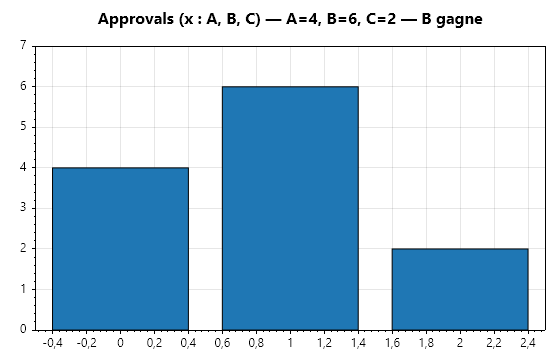


warning CS1701: En supposant que la référence d'assembly 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' utilisée par 'Microsoft.DotNet.Interactive' correspond à l'identité 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' de 'Microsoft.AspNetCore.Html.Abstractions', il se peut que vous deviez fournir une stratégie runtime



In [11]:
#r "nuget: ScottPlot, 5.0.55"

// Figure : scores d'approbation (A, B, C) du profil de l'expérience.
var appScores11 = C11.ScoresApprobation(approval11, cands11);
double[] xs11 = { 0, 1, 2 };
double[] ys11 = { appScores11["A"], appScores11["B"], appScores11["C"] };

var plt11 = new ScottPlot.Plot();
plt11.Add.Bars(xs11, ys11);
plt11.Axes.SetLimits(-0.5, 2.5, 0, 7);
plt11.Title($"Approvals (x : A, B, C) — A={appScores11["A"]}, B={appScores11["B"]}, C={appScores11["C"]} — B gagne");

string fig11 = plt11.GetPngHtml(560, 360);
display(HTML(fig11));

## À retenir

- Le vote par **approbation** remplace le classement par un bulletin : approuvés, non approuvés,
  et rien entre les deux. Ce n'est pas l'axiome d'indépendance qui tombe — sur ses propres
  bulletins, le compteur n'en trouve **aucune** violation. C'est le **domaine** qui change : la
  règle ne reçoit plus les classements complets que le théorème d'Arrow suppose.
- **Aucun bulletin n'est dominant.** Pour un électeur qui préfère `A > B > C`, seuls `{A}` et
  `{A, B}` ne sont dominés par aucun autre bulletin, et aucun des deux ne domine l'autre :
  approuver ou non le candidat du milieu est un choix, qui dépend du vote des autres.
- Un bulletin ne pèse que d'**un point**. Sur le duel, un électeur isolé ne change rien ; deux
  suffisent, parce que l'égalité qu'ils créent est départagée en leur faveur.
- Dès qu'on fabrique les bulletins depuis un classement (« ses deux premiers choix »), on revient
  sur le terrain d'Arrow : l'axiome casse, et le compteur le mesure — 4 224 violations.
- Le seuil reste un choix **stratégique**, et la règle a un **coût propre** : le risque d'élire un
  **consensus de repli** que personne ne met en tête, devant le favori de la majorité.

Changer de bulletin, c'est changer de réponse — et déplacer la question : le théorème d'Arrow
n'a plus prise, mais le calcul et le seuil restent.


## Exercices (suite)

L'exercice 1 accompagnait la matrice de dominance. Trois autres prolongent le carnet.

### Exercice 2 — Ex-aequo d'approbation

La règle départage les ex-æquo par ordre alphabétique. Construisez un profil de deux bulletins
sur trois candidats qui laisse **deux candidats au même score** d'approbation, et observez
comment le départage tranche.

- **Indice** : un profil où chacun des deux candidats est approuvé une fois suffit.


In [12]:
// Exercice 2 — Ex-aequo d'approbation
// Objectif : 2 bulletins sur 3 candidats, deux candidats à score ÉGAUX.
// Indice : un profil où chacun des deux est approuvé une fois.
List<HashSet<string>> ex11b = new List<HashSet<string>>
{
    // TODO etudiant : remplissez les deux bulletins
};
// string ex11b_g = C11.GagnantApprobation(ex11b, new[] { "A", "B", "C" });
// Console.WriteLine("Gagnant (tie-break alpha) : " + ex11b_g);
Console.WriteLine("Exercice 2 à compléter");


Exercice 2 à compléter


### Exercice 3 — Regret du votant

Pour chaque bulletin du profil `approval11`, calculez la différence entre le score d'approbation
du candidat que le votant met **en tête** (son 1er choix) et le score du gagnant.

- **Indice** : `C11.ScoresApprobation()` donne tous les scores ; le 1er choix est le 1er élément
  du classement correspondant (`classements11`).


In [13]:
// Exercice 3 — Regret du votant
// Objectif : pour CHAQUE bulletin de approval11, la différence entre le score du 1er choix
//   du votant et le score du gagnant par approbation.
// Indice : C11.ScoresApprobation() donne tous les scores ; le 1er choix est le 1er élément
//   du classement correspondant (classements11).
double[] regrets11 = { 0, 0, 0, 0, 0, 0 };   // TODO etudiant : remplissez
Console.WriteLine("Exercice 3 à compléter — regrets : " + string.Join(", ", regrets11));


Exercice 3 à compléter — regrets : 0, 0, 0, 0, 0, 0


### Exercice 4 — Le consensus sans premier choix

L'expérience du carnet a élu un candidat que personne ne classe en tête. Généralisez : construisez
un autre profil d'au moins 4 votants où le gagnant par approbation est mis en **1re place par
zéro** votant.


In [14]:
// Exercice 4 — Le consensus sans premier choix
// Objectif : un profil (>= 4 votants) dont le gagnant par approbation est mis en 1re place
//   par ZÉRO votant. L'expérience du carnet en est un ; généralisez-la.
List<HashSet<string>> ex11d = new List<HashSet<string>>();
// bool ex11d_ok = ...;   // TODO etudiant
Console.WriteLine("Exercice 4 à compléter");


Exercice 4 à compléter


## Pour aller plus loin

- **ChoixSocial-01** — le théorème d'Arrow et son compteur d'indépendance, que ce carnet réutilise.
- **ChoixSocial-05** — Gibbard-Satterthwaite : le stratégisme sur les classements, formalisé.
- **ChoixSocial-07** — l'approbation transposée aux **comités** (core, approbation multipartite).
- **Ce que ce carnet ne dit pas.** Il a mesuré l'approbation à trois candidats et trois à six
  votants, avec un départage alphabétique. La matrice de dominance donne la même réponse à deux
  et trois autres votants — et une réponse plus pauvre à un seul. Le compteur d'indépendance, lui,
  n'a été mené que sur un seul électorat : ses totaux valent pour ce qui a été compté.
- **En pratique (à documenter)** : le vote par approbation sert dans des scrutins réels. Ce
  carnet n'en cite aucun exemple de source : qui veut en citer un cherche d'abord le texte
  fondateur (règlement, loi électorale) et le motif annoncé, plutôt que la réputation de la règle.
